# E16 · Pseudo-labelling round 5: the E15a ensemble as teacher

E12 concluded that pseudo-labelling had saturated: a student trained on one teacher's labels only re-learns what that
teacher already believes. E15a (E09a + E12a + AdaBN + E13a + AdaBN, averaged) is the first teacher that is better than
any single model (**72.81%** vs 72.67%) and more stable (view agreement 92.0% vs 90.5%). Its labels come from three
models that make different mistakes, so they should be cleaner and cover more of the uncertain vegetation images.

Everything else is the **E09a setup**: EfficientNet-B0, 12 bands, `hist_split`, contrast augmentation, all Kaggle
images whose 8 averaged views agree, SeaLake capped at 400, used 2× per epoch. One change: the teacher.

**Questions:** does an ensemble teacher give more and different pseudo-labels than E09a did in E12, and does the
student beat E09a on its own? The student is also a candidate for a new ensemble with the E15a members.

**Train or load.** `LOAD_RUNS["E16a"] = None` trains. After training, set it to the new run folder and commit the
weights if the run is submitted (`git add -f runs/<run>/model.pt`).

## 1 · Setup and data

In [1]:
import json
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import CLASSES, PROJECT_ROOT, TEST_BANDS
from src.experiment import (add_pseudo_labels, class_mix, compare_variants, find_run, finish_run, kaggle_monitor,
                            kaggle_score, load_experiment_data, load_saved_model, plot_class_mix,
                            plot_variant_curves, select_view_agree, teacher_predictions, view_agreement)
from src.models import MEDIUM_TRACK_LIMIT, build_model
from src.plot_style import apply_style
from src.training import Normalizer, TrainConfig, fit, load_run, predict_views
from src.utils import describe_device, get_device, seed_everything

apply_style()

# ---- Experiment settings ---------------------------------------------------------------
NOTEBOOK = "E16_pseudo_labels_ensemble"
LOAD_RUNS = {   # saved runs; None = train this variant again
    "E16a": None,
}
TEACHERS = {    # the E15a ensemble members, as submitted
    "E09a": "pl_r3_view_agree_contrast_aug_hist_split_effb0",
    "E12a+AdaBN": "adabn_balanced_pl_r4_view_agree_contrast_aug_hist_split_effb0",
    "E13a+AdaBN": "adabn_balanced_indices_pl_r3_view_agree_contrast_aug_hist_split_effb0",
}
E12_TEACHER = "pl_r3_view_agree_contrast_aug_hist_split_effb0"   # E09a alone: round 4 (E12a), for comparison
CAPS = {"SeaLake": 400}
REPEAT = 2
MODEL = "efficientnet_b0"
BANDS = list(TEST_BANDS)
SEED = 42
cfg = TrainConfig(epochs=20, batch_size=128, lr=1e-3, weight_decay=1e-4,
                  label_smoothing=0.1, patience=5, augment=True,
                  photometric={"contrast": (0.9, 1.5), "band_contrast": (0.9, 1.15),
                               "brightness": (0.93, 1.07), "p": 0.8})   # as in E09a
# -----------------------------------------------------------------------------------------

seed_everything(SEED)
device = get_device()
print("Device:", describe_device(device))
results = {}

data = load_experiment_data(BANDS, ["hist_split"], device)
print(data.summary())


def base_config(variant, run_name, description, pseudo_labels):
    return {"run_name": run_name, "description": description, "notebook": NOTEBOOK, "variant": variant,
            "model": MODEL, "bands": BANDS, "corrections": ["hist_split"], "train": asdict(cfg),
            "split": "split_seed42", "pseudo_labels": pseudo_labels}

Device: Apple GPU (MPS)
train 18,900  val 4,050  internal test 4,050  Kaggle test 4,232


## 2 · Ensemble teacher and selection

Each member predicts the 8 views of every Kaggle image with its own bands and input layer; the views are averaged over
the members, exactly as in E15a. An image is kept when all 8 averaged views agree.

In [2]:
member_views = {}
for name, run in TEACHERS.items():
    model, normalizer, config = load_run(find_run(run), device)
    idx = torch.tensor([TEST_BANDS.index(b) for b in config["bands"]], device=device)
    member_views[name] = predict_views(model, data.kg_images[:, idx], normalizer)
    del model
    if device.type == "mps":
        torch.mps.empty_cache()

views = np.mean(list(member_views.values()), axis=0)       # (8, N, 10)
teacher_prob = views.mean(0)
pred = teacher_prob.argmax(1)
table = pd.DataFrame({"pred": np.array(CLASSES)[pred], "conf": teacher_prob.max(1),
                      "view_agree": (views.argmax(2) == pred).all(0)})
hard_idx = select_view_agree(table, CAPS, SEED)

r4_table, _ = teacher_predictions(E12_TEACHER, data, device)   # what E12a was trained on
r4_idx = select_view_agree(r4_table, CAPS, SEED)
same = np.intersect1d(hard_idx, r4_idx)
print(f"Round 5 (ensemble): {len(hard_idx):,} pseudo-labels (round 4, E09a alone: {len(r4_idx):,}); "
      f"{len(same):,} images in both, of which {(table.loc[same, 'pred'] != r4_table.loc[same, 'pred']).sum()} "
      f"with a different label")
pd.DataFrame({"8 views agree (ensemble)": table.loc[table["view_agree"], "pred"].value_counts(),
              "round 5 (E16a)": table.loc[hard_idx, "pred"].value_counts(),
              "round 4 (E12a)": r4_table.loc[r4_idx, "pred"].value_counts(),
              "lowest conf (round 5)": table.loc[hard_idx].groupby("pred")["conf"].min()}).reindex(CLASSES).round(2)

Round 5 (ensemble): 3,275 pseudo-labels (round 4, E09a alone: 3,211); 3,098 images in both, of which 0 with a different label


,8 views agree (ensemble),round 5 (E16a),round 4 (E12a),lowest conf (round 5)
pred,,,,
AnnualCrop,322,322,317,0.56
Forest,407,407,405,0.47
HerbaceousVegetation,379,379,367,0.54
Highway,328,328,323,0.54
Industrial,241,241,233,0.57
Pasture,247,247,243,0.48
PermanentCrop,326,326,320,0.52
Residential,386,386,368,0.59
River,239,239,235,0.51


## 3 · E16a · E09a setup, ensemble pseudo-labels

In [3]:
tr_images, tr_labels, _ = add_pseudo_labels(data, table, hard_idx, repeat=REPEAT)
if LOAD_RUNS["E16a"]:
    model, normalizer, history = load_saved_model(LOAD_RUNS["E16a"], device)
    best_state = None
else:
    seed_everything(SEED)
    normalizer = Normalizer.fit(data.X_tr)
    model = build_model(MODEL, bands=BANDS, pretrained=True).to(device)
    history, best_state = fit(model, tr_images, tr_labels, data.va_images, data.va_labels,
                              normalizer, cfg, monitor=kaggle_monitor(data, normalizer))

results["E16a"] = finish_run(model, normalizer, history, best_state, data, variant="E16a", load_run=LOAD_RUNS["E16a"],
    device=device, seed=SEED, param_limit=MEDIUM_TRACK_LIMIT,
    config=base_config("E16a", "pl_r5_ensemble_view_agree_contrast_aug_hist_split_effb0",
                       "hist_split + contrast aug + pseudo-labels round 5 (E15a ensemble teacher, 8 views agree), 2x",
                       {"teacher": "E15a ensemble: " + ", ".join(TEACHERS.values()), "selection": "view_agree",
                        "caps": CAPS, "repeat": REPEAT, "n_images": int(len(hard_idx))}))
del tr_images, tr_labels

Pseudo-labelled Kaggle images: 3,275 of 4,232, used 2x (25.7% of the training set, 25,450 images)
epoch  1  train loss 1.494 acc 0.591  val loss 0.329 acc 0.925 *  val_conf 0.818  kg_conf 0.727  kg_sealake 0.241  kg_share_AnnualCrop 0.111  kg_share_Forest 0.131  kg_share_HerbaceousVegetation 0.095  kg_share_Highway 0.085  kg_share_Industrial 0.052  kg_share_Pasture 0.078  kg_share_PermanentCrop 0.069  kg_share_Residential 0.091  kg_share_River 0.047  kg_share_SeaLake 0.241  (51s)
epoch  2  train loss 0.742 acc 0.906  val loss 0.200 acc 0.963 *  val_conf 0.872  kg_conf 0.814  kg_sealake 0.244  kg_share_AnnualCrop 0.059  kg_share_Forest 0.098  kg_share_HerbaceousVegetation 0.114  kg_share_Highway 0.080  kg_share_Industrial 0.060  kg_share_Pasture 0.060  kg_share_PermanentCrop 0.134  kg_share_Residential 0.092  kg_share_River 0.057  kg_share_SeaLake 0.244  (47s)
epoch  3  train loss 0.655 acc 0.941  val loss 0.186 acc 0.969 *  val_conf 0.877  kg_conf 0.831  kg_sealake 0.243  kg_share_Annu

## 4 · Comparison with the teacher (E15a) and E09a

The student has to come close to its teacher to be useful on its own; even a little below it, it can replace or join
an ensemble member. `compare_variants` measures E16a with AdaBN; the rows below add E09a and E15a without AdaBN.

In [4]:
summary = compare_variants(results, reference=teacher_prob, reference_name="E15a")
e09 = member_views["E09a"]
summary.loc["E09a"] = pd.Series({"description": "best single model", "confidence (%)": e09.mean(0).max(1).mean() * 100,
                       "view agreement (%)": view_agreement(e09) * 100,
                       "same class as E15a (%)": (e09.mean(0).argmax(1) == pred).mean() * 100,
                       "Kaggle public (%)": kaggle_score(find_run(TEACHERS["E09a"]))})
summary.loc["E15a (teacher)"] = pd.Series({"description": "ensemble teacher", "confidence (%)": teacher_prob.max(1).mean() * 100,
                                 "view agreement (%)": view_agreement(views) * 100, "same class as E15a (%)": 100.0,
                                 "Kaggle public (%)": kaggle_score(find_run("ensemble_e15a_e09a_e12a_e13a"))})
for k, r in results.items():
    summary.loc[k, "no AdaBN: same class as E15a (%)"] = (r.kg_prob.argmax(1) == pred).mean() * 100
summary.round(2)

,description,internal test (%),confidence (%),view agreement (%),same class as E15a (%),Kaggle public (%),no AdaBN: same class as E15a (%)
E16a,hist_split + contrast aug + pseudo-labels roun...,98.888889,87.386436,93.383743,96.691871,None,96.83
E09a,best single model,NaN,87.362061,90.500945,97.613422,72.671,NaN
E15a (teacher),ensemble teacher,NaN,85.215599,92.036862,100.0,72.812,NaN


In [5]:
# Different predictions: E15a's class (rows) -> E16a's class, no AdaBN (columns)
teacher_names = np.array(CLASSES)[pred]
for k, r in results.items():
    new = np.array(CLASSES)[r.kg_prob.argmax(1)]
    changed = new != teacher_names
    print(f"{k}: {changed.sum()} images differ from E15a ({changed.mean():.1%})")
    display(pd.crosstab(teacher_names[changed], new[changed]).rename_axis(index="E15a", columns=k))

E16a: 134 images differ from E15a (3.2%)


E16a,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River
E15a,,,,,,,,,
AnnualCrop,0,1,1,3,0,4,16,0,0
Forest,0,0,3,0,0,4,1,0,1
HerbaceousVegetation,0,13,0,1,0,5,3,3,1
Highway,3,0,2,0,0,0,0,1,1
Industrial,0,0,1,4,0,1,3,3,0
Pasture,1,1,2,1,0,0,3,0,0
PermanentCrop,15,4,2,2,1,4,0,1,0
Residential,0,1,0,0,6,0,3,0,0
River,0,0,3,0,1,0,0,1,0


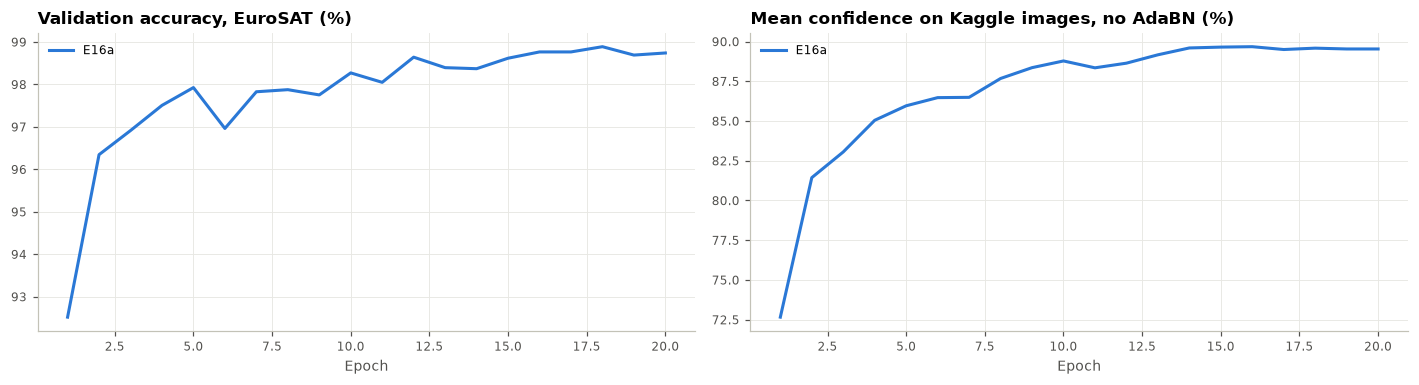

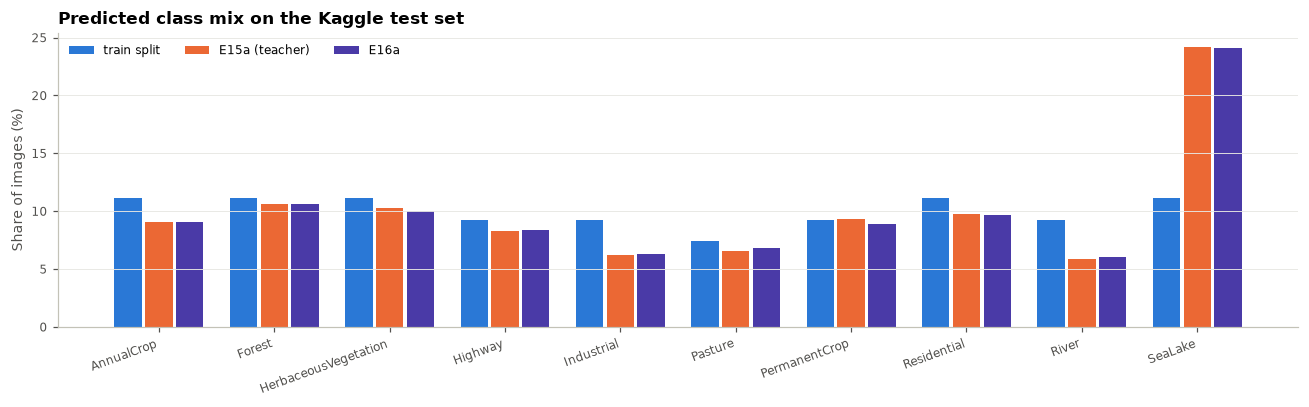

In [6]:
plot_variant_curves(results)
plot_class_mix(pd.DataFrame({"train split": class_mix(np.eye(10)[data.y_tr]), "E15a (teacher)": class_mix(teacher_prob),
                             **{k: class_mix(r.prob_ada) for k, r in results.items()}}))

## 5 · Conclusion

*To fill in after the Kaggle submission (both files: with and without AdaBN).*

| Model | Pseudo-labels | Kaggle public (no AdaBN / AdaBN) |
|---|---|---|
| E09a | round 3, E06c + AdaBN | 72.67% / 71.78% |
| E12a | round 4, E09a | 72.34% / 72.39% |
| E15a (ensemble, teacher) | – | **72.81%** |
| E16a | round 5, E15a ensemble | |

If E16a is close to E15a, try it as an extra or replacement member in E15 (e.g. E09a + E13a + AdaBN + E16a).